# Denoising Autoencoder

Sticking with the MNIST dataset, let's add noise to our data and see if we can define and train an autoencoder to _de_-noise the images.

<img src='images/autoencoder_denoise.png' width=50%/>

Let's get started by importing our libraries and getting the dataset.

In [1]:
# The MNIST datasets are hosted on yann.lecun.com that has moved under CloudFlare protection
# Run this script to enable the datasets download
# Reference: https://github.com/pytorch/vision/issues/1938
from six.moves import urllib
opener = urllib.request.build_opener()
opener.addheaders = [('User-agent', 'Mozilla/5.0')]
urllib.request.install_opener(opener)

In [2]:
import torch
import numpy as np
from torchvision import datasets
import torchvision.transforms as transforms

# convert data to torch.FloatTensor
transform = transforms.ToTensor()

# load the training and test datasets
train_data = datasets.MNIST(root='~/.pytorch/MNIST_data/', train=True,
                                   download=True, transform=transform)
test_data = datasets.MNIST(root='~/.pytorch/MNIST_data/', train=False,
                                  download=True, transform=transform)

# Create training and test dataloaders
num_workers = 0
# how many samples per batch to load
batch_size = 20

# prepare data loaders
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, num_workers=num_workers)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, num_workers=num_workers)

### Visualize the Data

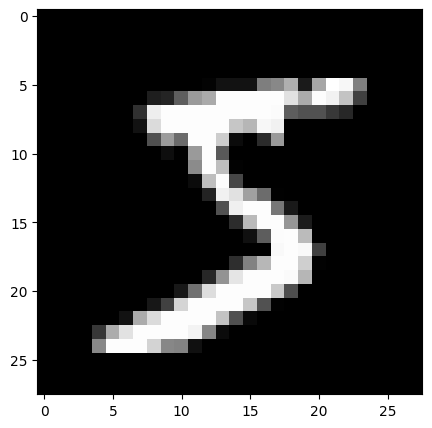

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline
    
# obtain one batch of training images
dataiter = iter(train_loader)
images, labels = dataiter.__next__()
images = images.numpy()

# get one image from the batch
img = np.squeeze(images[0])

fig = plt.figure(figsize = (5,5)) 
ax = fig.add_subplot(111)
ax.imshow(img, cmap='gray')

---
# Denoising

As I've mentioned before, autoencoders like the ones you've built so far aren't too useful in practive. However, they can be used to denoise images quite successfully just by training the network on noisy images. We can create the noisy images ourselves by adding Gaussian noise to the training images, then clipping the values to be between 0 and 1.

We'll use noisy images as input and the original, clean images as targets.** 

Below is an example of some of the noisy images I generated and the associated, denoised images.

<img src='images/denoising.png' />


Since this is a harder problem for the network, we'll want to use _deeper_ convolutional layers here; layers with more feature maps. You might also consider adding additional layers. I suggest starting with a depth of 32 for the convolutional layers in the encoder, and the same depths going backward through the decoder.

**TODO**: Build the network for the denoising autoencoder. Add deeper and/or additional layers compared to the model we used beforehand.

In [8]:
import torch.nn as nn
import torch.nn.functional as F

# define the NN architecture
class ConvDenoiser(nn.Module):
    def __init__(self):
        super(ConvDenoiser, self).__init__()
        # encoder
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 16, 3, padding=1)
        self.conv3 = nn.Conv2d(16, 8, 3, padding=1)
        self.maxpool = nn.MaxPool2d(2, 2)

        # decoder layers
        # transpose layer, 
        self.t_conv1 = nn.ConvTranspose2d(8, 8, 3, stride=2)
        self.t_conv2 = nn.ConvTranspose2d(8, 16, 2, stride=2)
        self.t_conv3 = nn.ConvTranspose2d(16, 32, 2, stride=2)

        # one, final, normal conv layer to decrease the depth
        self.conv_out = nn.Conv2d(32, 1, 3, padding=1)

    def forward(self, x):
        # encode layers
        # first layer
        x = F.relu(self.conv1(x))
        x = self.maxpool(x)
        # second layer
        x = F.relu(self.conv2(x))
        x = self.maxpool(x)
        # third layer
        x = F.relu(self.conv3(x))
        x = self.maxpool(x)     # compressed representation

        # decoder
        x = F.relu(self.t_conv1(x))
        x = F.relu(self.t_conv2(x))
        x = F.relu(self.t_conv3(x))
        x = torch.sigmoid(self.conv_out(x))

        return x

# initialize the NN
model = ConvDenoiser()
print(model)

ConvDenoiser(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (t_conv1): ConvTranspose2d(8, 8, kernel_size=(3, 3), stride=(2, 2))
  (t_conv2): ConvTranspose2d(8, 16, kernel_size=(2, 2), stride=(2, 2))
  (t_conv3): ConvTranspose2d(16, 32, kernel_size=(2, 2), stride=(2, 2))
  (conv_out): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
)


---
## Training

We are only concerned with the training images, which we can get from the `train_loader`.

In this case, we are actually **adding some noise** to these images and we'll feed these `noisy_imgs` to our model. The model will produce reconstructed images based on the noisy input. But, we want it to produce _normal_ un-noisy images, and so, when we calculate the loss, we will still compare the reconstructed outputs to the original images!

Because we're comparing pixel values in input and output images, it will be best to use a loss that is meant for a regression task. Regression is all about comparing quantities rather than probabilistic values. So, in this case, I'll use `MSELoss`. And compare output images and input images as follows:
```
loss = criterion(outputs, images)
```

In [9]:
# specify loss function
criterion = nn.MSELoss()

# specify loss function
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [10]:
# check if CUDA is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [11]:
# number of epochs to train the model
n_epochs = 20

# move model to GPU if available
model.to(device)

# for adding noise to images
noise_factor=0.5

for epoch in range(1, n_epochs+1):
    model.train()
    # monitor training loss
    train_loss = 0.0
    
    for images, _ in train_loader:
        # no flattening needed for conv nets
        # move to device
        images = images.to(device)
        
        ## add random noise to the input images
        noisy_imgs = images + noise_factor * torch.randn(*images.shape).to(device)
        # Clip the images to be between 0 and 1
        noisy_imgs = torch.clamp(noisy_imgs, 0., 1.)
                
        # clear the gradients of all optimized variables
        optimizer.zero_grad()
        # forward pass: compute predicted outputs by passing *noisy* images to the model
        outputs = model(noisy_imgs)
        # calculate the loss
        # the "target" is still the original, not-noisy images
        loss = criterion(outputs, images)
        # backward pass: compute gradient of the loss with respect to model parameters
        loss.backward()
        # perform a single optimization step (parameter update)
        optimizer.step()
        # update running training loss
        train_loss += loss.item()
            
    # print avg training statistics 
    train_loss /= len(train_loader) 
    print(f"Epoch: {epoch}\tTraining Loss: {train_loss:.6f}")


Epoch: 1	Training Loss: 0.045064
Epoch: 2	Training Loss: 0.028761
Epoch: 3	Training Loss: 0.026193
Epoch: 4	Training Loss: 0.024840
Epoch: 5	Training Loss: 0.023736
Epoch: 6	Training Loss: 0.022730
Epoch: 7	Training Loss: 0.021938
Epoch: 8	Training Loss: 0.021277
Epoch: 9	Training Loss: 0.020822
Epoch: 10	Training Loss: 0.020473
Epoch: 11	Training Loss: 0.020233
Epoch: 12	Training Loss: 0.020023
Epoch: 13	Training Loss: 0.019806
Epoch: 14	Training Loss: 0.019616
Epoch: 15	Training Loss: 0.019351
Epoch: 16	Training Loss: 0.019156
Epoch: 17	Training Loss: 0.018999
Epoch: 18	Training Loss: 0.018889
Epoch: 19	Training Loss: 0.018826
Epoch: 20	Training Loss: 0.018733


## Checking out the results

Here I'm adding noise to the test images and passing them through the autoencoder. It does a suprising great job of removing the noise, even though it's sometimes difficult to tell what the original number is.

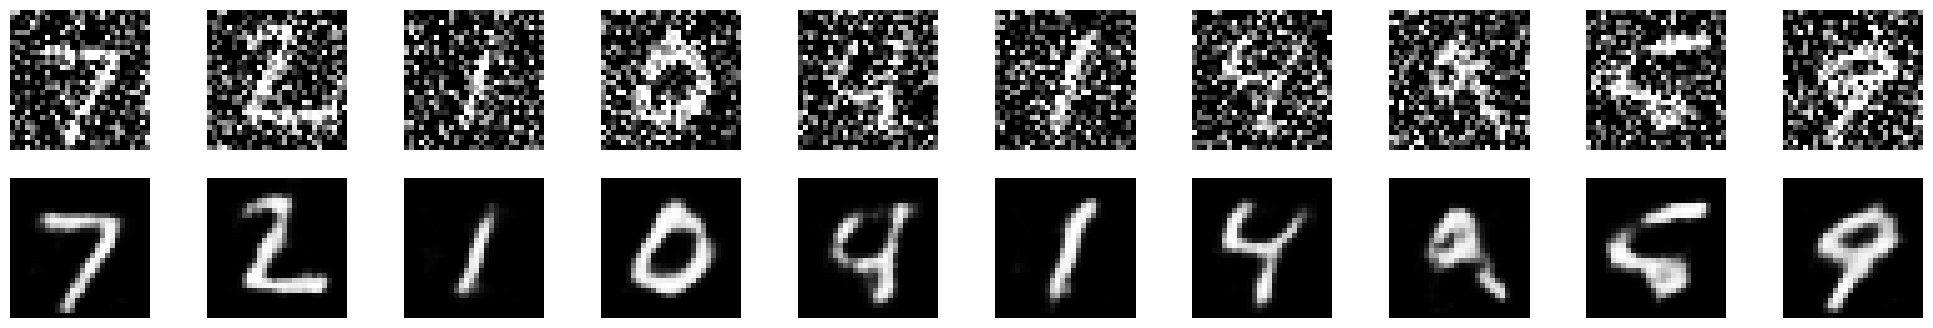

In [12]:
dataiter = iter(test_loader)
images, labels = next(dataiter)

model.eval()
with torch.no_grad():
    images = images.to(device)

    # add noise
    noise = noise_factor * torch.randn_like(images)
    noisy_imgs = torch.clamp(images + noise, 0.0, 1.0)

    # denoise / reconstruct
    output = model(noisy_imgs)

# move to CPU for plotting
noisy_np = noisy_imgs.detach().cpu().numpy()
output_np = output.detach().cpu().numpy()  # already (B,1,28,28)

# plot
n_show = 10
fig, axes = plt.subplots(2, n_show, sharex=True, sharey=True, figsize=(25,4))

for imgs, row in zip([noisy_np, output_np], axes):
    for img, ax in zip(imgs[:n_show], row):
        ax.imshow(np.squeeze(img), cmap="gray")
        ax.axis("off")